In [1]:
import numpy as np
from pathlib import Path
import timeit
import pandas as pd
import sys
sys.path.insert(1, '../')
import util
from util.dynamics import temp_response, environmental_update

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D

import tqdm
import seaborn as sns
from scipy.optimize import fsolve

# Reading data

In [2]:
df_TEs = pd.read_excel('../../Data/TEsummary.xlsx',header=[0],index_col=0)
T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy() # Critical threshold for tipping
betas = df_TEs['Beta (1/°C)'].to_numpy() # Logistic parameter (temp. sensitivity)
q_c = 1/(1+df_TEs['Collapse (years)'].to_numpy()) # collapse leverage
q_r = 1/(1+df_TEs['Recovery (years)'].to_numpy())

In [3]:
# Reading extended SSP temperatures
years = np.arange(1850, 2351) 
no_years = len(years)
df = pd.read_excel('../../Data/extendedSSPs.xlsx')
scenarios = df['scenario'].unique()
dfs = {s: df[df['scenario']==s].set_index('quantile').iloc[:,9:].transpose() for s in scenarios}

# Loading pre-saved interaction matrices
len_sample=500
A = [np.loadtxt('../../Data/Interaction matrices/A_%s.csv'%r) for r in range(len_sample)]

# Extended ssps as sanity check

## Simulations

In [ ]:
# -------- SIMULATIONS --------------
# Modifying collapse probabilities for each year according to each scenario
p_c = np.ones((len(scenarios),no_years,len(df_TEs)))
p_c *= q_c

p_r = np.ones((len(scenarios),no_years,len(df_TEs)))
p_r *= q_r

for t in range(no_years):
    for i,s in enumerate(scenarios):
        p_c[i,t,:] *= temp_response(dfs[s]['mean'].to_numpy()[t], T_lim, betas)
        p_r[i,t,:] *= (1-temp_response(dfs[s]['mean'].to_numpy()[t], T_lim, betas))

In [ ]:
fig,ax=util.plot.TE_3x3_fig(ylabel='Probability')
for i in range(len(df_TEs)):
    ax[i//3,i%3].plot(years,p_c[2,:,i],color='red',label='Collapse')
    ax[i//3,i%3].plot(years,p_r[2,:,i],color='green',label='Recovery')

In [ ]:
D = np.zeros((len(scenarios),len_sample,len(df_TEs),no_years))
for r in (range(len_sample)):
    for j in range(len(scenarios)):
        for t in range(1,no_years):
            D[j,r,:,t] = environmental_update(D[j,r,:,t-1],A[r],pc=p_c[j,t,:],pr=p_r[j,t,:])

# Simulating dynamics for TEs without interactions
D_noint = np.zeros((len(scenarios),len(df_TEs),no_years))
for t in (range(1,no_years)):
    for j in range(len(scenarios)):
        D_noint[j,:,t] = environmental_update(D_noint[j,:,t-1],np.zeros((len(df_TEs),len(df_TEs))),pc=p_c[j,t,:],pr=p_r[j,t,:])

## Plotting results

In [ ]:
fig,axs = util.plot.TE_3x3_fig()
TEs = df_TEs.index.to_numpy()
TE_ind = {te:i for i,te in enumerate(TEs)}
TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
linestyles = [':'] + [(0,(2*j+2,1)) for j in range(len(scenarios)-2)] + ['-']
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    for j in range(len(scenarios)):
        axs[i_ax//3,i_ax%3].plot(years,D[j,:,i,:].mean(axis=0)*100,
                                 c=util.plot.lighten_color(colors[i],1),#0.1+(j+3)/(len(scenarios)+3)), 
                                 ls=linestyles[j],
                                 lw=1.5)
        # axs[i_ax//3,i_ax%3].fill_between(years,
        #                                  np.quantile(D[j,:,i,:],0.05,axis=0)*100,
        #                                  np.quantile(D[j,:,i,:],0.95,axis=0)*100,
        #                                  color=util.plot.lighten_color(colors[i],1),#0.1+(j+3)/(len(scenarios)+3)), 
        #                                  alpha=0.3,
        #                                  lw=1,edgecolor='none')

# Parametrised TIPMIP

In [4]:
def TIPMIP_temps(T_peak=2.5, T_conv=0, t_peak=200, t_end = 5000):
    # hard coded speed of ramp up and ramp down as +- 0.2C/decade
    # also hard coded each time step as 1 year
    if T_peak < T_conv:
        raise ValueError("T_peak is smaller than T_conv, this would be an undershoot not overshoot.")

    temp = np.concatenate((np.arange(0,T_peak+.01,step=0.02), # ramp up from 0 -> T_peak at a rate of +0.2C/dec
                           np.ones(t_peak)*T_peak, # remain at peak for t_peak years
                           np.arange(T_conv,T_peak,step=0.02)[::-1])) # ramp down from T_peak -> T_conv at a rate of -0.2C/dec
    if t_end <= len(temp):
        return temp[:t_end]                          
    else:
        return np.concatenate((temp, np.ones(t_end-len(temp))*T_conv)) # remain at T_conv for t_at_conv years

In [5]:
t_peaks = np.arange(50,201,step=10)
T_peaks = np.arange(1.0,4.1,step=0.1)
t_end=1000

Temp = np.array( [[TIPMIP_temps(T_peak=T,t_peak=t,t_end=t_end,T_conv=0) for t in t_peaks] for T in T_peaks])

In [6]:
D = np.zeros((len_sample, len(T_peaks), len(t_peaks), len(df_TEs), t_end+1))
for r in tqdm.tqdm(range(len_sample)):
    for i,T_p in enumerate(T_peaks):
        for j,t_p in enumerate(t_peaks):
            for t in range(1,t_end+1):
                # environmental_update(D[j,r,:,t-1],A[r],pc=p_c[j,t,:],pr=p_r[j,t,:])
                D[r, i, j, :, t] =  environmental_update(D[r, i, j, :, t-1], A[r], 
                                                      pc=q_c*temp_response(Temp[i,j,t-1], T_lim, betas),
                                                      pr=q_r*(1-temp_response(Temp[i,j,t-1], T_lim, betas)))
            # np.array([environmental_update(np.zeros(9), A[r], t_end, 
            #                                       T = TIPMIP_temps(T_peak=T,t_peak=t,t_end=t_end,T_conv=0), 
            #                                       tau_c=tau_c,pr=pr, beta=beta,T_lim=T_lim) for r in range(len_sample)]).mean(axis=0)

100%|██████████████████████████████████████████████████████████████████████████████| 500/500 [1:16:54<00:00,  9.23s/it]


In [7]:
D.shape

(500, 31, 16, 9, 1001)

In [10]:
D_tot_risk = D.mean(axis=0).sum(axis=2)

In [11]:
D_tot_risk.shape

(31, 16, 1001)

In [ ]:
extent = [50-5, 200+5, 1-0.05, 4+0.05]
t = 201
im = plt.imshow(D_tot_risk[:,:,t],extent=extent,origin='lower',aspect='auto',cmap='magma_r')
plt.contour(D_tot_risk[:,:,t],np.arange(0.5,5,step=0.5), extent=extent,colors='white')
plt.colorbar(im)

In [36]:
D.shape

(500, 31, 16, 9, 1001)

In [34]:
D.mean(axis=0).nbytes/1e6

35.747712

In [39]:
D_mean = D.mean(axis=0)
for i,T in enumerate(T_peaks):
    for j,t in enumerate(t_peaks):
        np.savetxt("../../Data/Simulations/Overshoots/temp_dep/T%.1f_t%s.csv"%(T,t), D_mean[i,j,:,:])

In [44]:
def overshoot_integral(t, T_peak,t_peak):
    t_ramp = T_peak/0.02
    if t < t_ramp:
        return 0.01*t**2
    elif t < t_ramp+t_peak:
        return 0.01*t_ramp**2 + (t-t_ramp)*T_peak
    elif t < 2*t_ramp + t_peak:
        return 0.01*t_ramp**2 + (t-t_ramp)*T_peak - 0.01*(t-t_ramp - t_peak)**2
    else:
        return T*(t_ramp+t_peak)

In [45]:
integral = np.zeros_like(D_mean[:,:,0,:])
for i,T in enumerate(T_peaks):
    for j,t in enumerate(t_peaks):
        for k in range(1001):
            integral[i,j,k] = overshoot_integral(k,T,t)

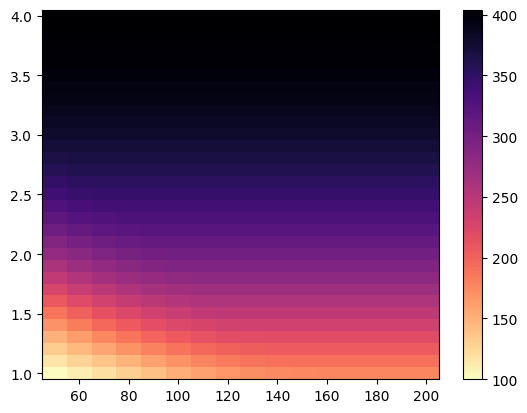

In [47]:
extent = [50-5, 200+5, 1-0.05, 4+0.05]
t = 201
im = plt.imshow(integral[:,:,t],extent=extent,origin='lower',aspect='auto',cmap='magma_r')
plt.colorbar(im)

In [48]:
integral.shape

(31, 16, 1001)

In [49]:
D_mean.shape

(31, 16, 9, 1001)

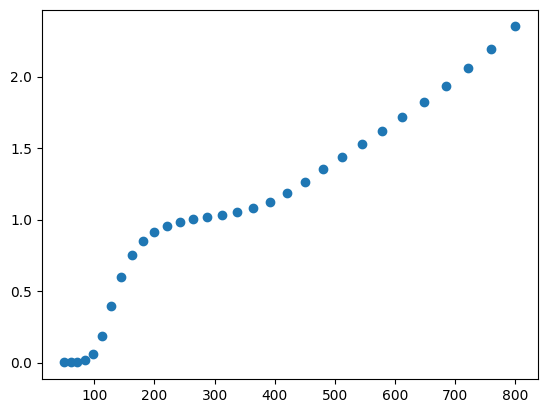

In [59]:
t = -1
plt.scatter([T**2/0.02 for T in T_peaks],[D_tot_risk[i,0,round(T/0.02)] for i,T in enumerate(T_peaks)])

In [78]:
D_tot_a = np.array([[D_tot_risk[i,j,round(T/0.02)] for j,t in enumerate(t_peaks)] for i,T in enumerate(T_peaks)])
D_tot_b = np.array([[D_tot_risk[i,j,round(T/0.02)+t] for j,t in enumerate(t_peaks)] for i,T in enumerate(T_peaks)])
D_tot_c = np.array([[D_tot_risk[i,j,round(T/0.01)+t] for j,t in enumerate(t_peaks)] for i,T in enumerate(T_peaks)])
D_tot_d = np.array([[D_tot_risk[i,j,round(T/0.01)+300] for j,t in enumerate(t_peaks)] for i,T in enumerate(T_peaks)])

Text(0, 0.5, 'Peak temperature (°C)')

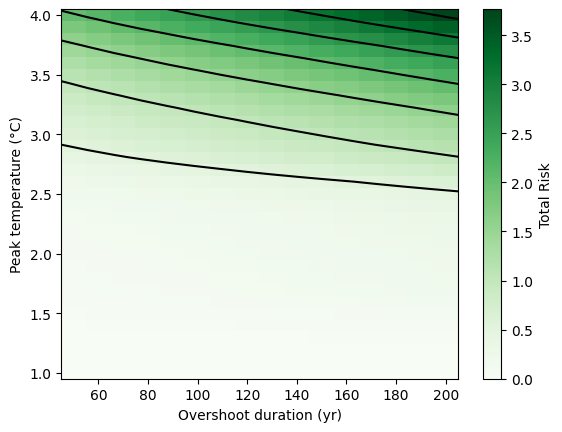

In [85]:
extent = [50-5, 200+5, 1-0.05, 4+0.05]
t = 601
im = plt.imshow(D_tot_risk[:,:,t],extent=extent,origin='lower',aspect='auto',cmap='Greens',vmin=0)
plt.contour(D_tot_risk[:,:,t],np.arange(0.5,5,step=0.5), extent=extent,colors='black')
plt.colorbar(im,label='Total Risk')
plt.xlabel('Overshoot duration (yr)')
plt.ylabel('Peak temperature (°C)')

In [61]:
D_tot_a.shape

(31, 16)